# Library

In [1]:
import torch
from torchvision import transforms as T
from torch.utils.data import DataLoader
import torch.nn as nn

from glob import glob
import os
import pandas as pd
from PIL import Image
from tqdm.notebook import tqdm

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

import psutil
import time

# Dataloader

In [2]:
class FrameImageDataset(torch.utils.data.Dataset):
    def __init__(self, 
    root_dir='/work3/ppar/data/ucf101',
    split='train', 
    transform=None
):
        self.frame_paths = [path.replace('\\', '/') for path in sorted(glob(f'{root_dir}/frames/{split}/*/*/*.jpg'))]
        self.df = pd.read_csv(f'{root_dir}/metadata/{split}.csv')
        self.split = split
        self.transform = transform
       
    def __len__(self):
        return len(self.frame_paths)

    def _get_meta(self, attr, value):
        return self.df.loc[self.df[attr] == value]

    def __getitem__(self, idx):
        frame_path = self.frame_paths[idx]
        video_name = frame_path.split('/')[-2]
        video_meta = self._get_meta('video_name', video_name)
        label = video_meta['label'].item()
        
        frame = Image.open(frame_path).convert("RGB")

        if self.transform:
            frame = self.transform(frame)
        else:
            frame = T.ToTensor()(frame)

        return frame, label

In [3]:
root_dir = '/dtu/datasets1/02516/ucf101_noleakage'

batch_size = 10

transform = T.Compose([T.Resize((64, 64)), T.ToTensor()])

train_set = FrameImageDataset(root_dir=root_dir, split='train', transform=transform)
test_set = FrameImageDataset(root_dir=root_dir, split='test', transform=transform)
val_set = FrameImageDataset(root_dir=root_dir, split='val', transform=transform)

train_loader = DataLoader(train_set,  batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_set,  batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_set,  batch_size=batch_size, shuffle=False)

action = ['BodyWeightSquats', 'HandstandPushups', 'HandstandWalking', 'JumpingJack', 'JumpRope', 'Lunges', 'PullUps', 'PushUps', 'TrampolineJumping', 'WallPushups']

# Sample from dataset

(-0.5, 63.5, 63.5, -0.5)

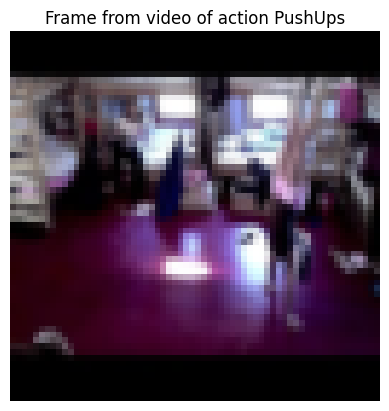

In [4]:
frames, labels = next(iter(train_loader))
label_num = labels[np.random.randint(labels.shape[0])]

plt.imshow(frames[label_num].permute(1, 2, 0).numpy())
plt.title(f"Frame from video of action {action[label_num]}")
plt.axis("off")

# 2D CNN

In [5]:
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()

        self.convolutional1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.convolutional2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.convolutional3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fully_connected = nn.Sequential(
            nn.Linear(64 * 8 * 8, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.convolutional1(x)
        x = self.convolutional2(x)
        x = self.convolutional3(x)

        x = x.view(x.size(0), -1)

        x = self.fully_connected(x)
        x = x.squeeze(1)

        return x

In [6]:
device = ("cuda" if torch.cuda.is_available() else "cpu")
print(device)

model = Network()
model.to(device)

optimizer = torch.optim.Adam(model.parameters(), weight_decay=1e-5, lr=0.001)
criterion = nn.CrossEntropyLoss()

cuda


# Training of 2D CNN

In [7]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
    train_losses, train_accs = [], []
    val_losses, val_accs = [], []
    memory_stats = []
    times_per_epoch = []
    
    for epoch in range(num_epochs):
        epoch_start = time.time()
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        batch_times = []
        for inputs, labels in tqdm(train_loader, total = len(train_loader)):
            batch_start = time.time()
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
            batch_times.append(time.time() - batch_start)
        
        train_loss = running_loss / len(train_loader)
        train_acc = 100. * correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        
        model.eval()
        running_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                running_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
        
        val_loss = running_loss / len(val_loader)
        val_acc = 100. * correct / total
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        
        memory_stats.append(get_memory_usage())
        epoch_time = time.time() - epoch_start
        times_per_epoch.append({
            'epoch_time': epoch_time,
            'avg_batch_time': np.mean(batch_times),
            'std_batch_time': np.std(batch_times)
        })
        
        print(f'Epoch {epoch+1}/{num_epochs}:')
        print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%')
        print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
        print(f'Time: {epoch_time:.2f}s, Batch avg: {np.mean(batch_times):.3f}s')
        print(f'Memory: {memory_stats[-1]}\n')
    
    return {
        'metrics': (train_losses, train_accs, val_losses, val_accs),
        'memory': memory_stats,
        'time': times_per_epoch
    }

def get_memory_usage():
    if torch.cuda.is_available():
        gpu_memory = torch.cuda.memory_allocated() / 1024**2
        gpu_cached = torch.cuda.memory_reserved() / 1024**2
        return {
            'gpu_allocated': gpu_memory,
            'gpu_cached': gpu_cached,
            'ram': psutil.Process().memory_info().rss / 1024**2
        }
    return {'ram': psutil.Process().memory_info().rss / 1024**2}

In [8]:
def evaluate_model(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0
    batch_times = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            start_time = time.time()
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            batch_times.append(time.time() - start_time)
    
    test_acc = 100. * correct / total
    memory_usage = get_memory_usage()
    
    print(f'Test Accuracy: {test_acc:.2f}%')
    print(f'Average inference time per batch: {np.mean(batch_times):.3f}s')
    print(f'Memory usage during inference: {memory_usage}')
    
    return {
        'accuracy': test_acc,
        'batch_times': batch_times,
        'memory': memory_usage
    }

In [10]:
train = False

if train == True:
    epoch = 10
    model_data = train_model(model, train_loader, device, optimizer, criterion, epoch)
    torch.save(model.state_dict(), os.getcwd().replace('\\', '/') + '/aggregate_per_frame_model.pt')
else:
    model.load_state_dict(torch.load(os.getcwd().replace('\\', '/') + '/aggregate_per_frame_model.pt', map_location=device, weights_only=True))
    model.eval()

Epoch 1/100:
Train Loss: 1.2792, Train Acc: 59.36%
Val Loss: 2.3588, Val Acc: 27.25%
Time: 11.21s, Batch avg: 0.004s
Memory: {'gpu_allocated': 51.67333984375, 'gpu_cached': 88.0, 'ram': 1055.765625}

Epoch 2/100:
Train Loss: 0.4477, Train Acc: 87.14%
Val Loss: 3.1911, Val Acc: 23.00%
Time: 10.82s, Batch avg: 0.004s
Memory: {'gpu_allocated': 51.67333984375, 'gpu_cached': 88.0, 'ram': 1056.02734375}

Epoch 3/100:
Train Loss: 0.3040, Train Acc: 90.98%
Val Loss: 3.1543, Val Acc: 28.92%
Time: 10.79s, Batch avg: 0.004s
Memory: {'gpu_allocated': 51.67333984375, 'gpu_cached': 88.0, 'ram': 1056.9140625}

Epoch 4/100:
Train Loss: 0.2416, Train Acc: 92.76%
Val Loss: 2.7469, Val Acc: 35.08%
Time: 10.77s, Batch avg: 0.004s
Memory: {'gpu_allocated': 51.67333984375, 'gpu_cached': 88.0, 'ram': 1056.9296875}

Epoch 5/100:
Train Loss: 0.1899, Train Acc: 94.30%
Val Loss: 2.9951, Val Acc: 30.58%
Time: 10.82s, Batch avg: 0.004s
Memory: {'gpu_allocated': 51.67333984375, 'gpu_cached': 88.0, 'ram': 1056.92968

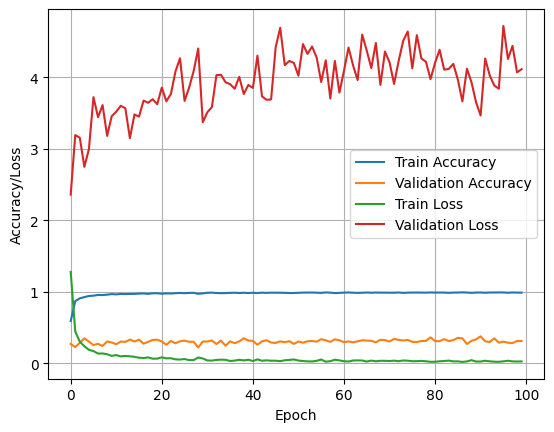

In [17]:
fig, ax = plt.subplots(1, 1)
ax.plot(np.array(model_data['metrics'][1]) / 100)
ax.plot(np.array(model_data['metrics'][3]) / 100)
ax.plot(model_data['metrics'][0])
ax.plot(model_data['metrics'][2])
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy/Loss')
ax.legend(['Train Accuracy', 'Validation Accuracy', 'Train Loss', 'Validation Loss'])
ax.grid()
fig.savefig('metrics_comparison.png')

In [12]:
eval = evaluate_model(model, test_loader, device)

Test Accuracy: 28.08%
Average inference time per batch: 0.001s
Memory usage during inference: {'gpu_allocated': 51.6728515625, 'gpu_cached': 88.0, 'ram': 1064.734375}


# Aggregator

In [13]:
def aggregate(model, dataloader, device):
    model.to(device)
    model.eval()
    prediction = []
    truth = []

    for frames, labels in dataloader:
        frames = frames.to(device)
        output = model(frames)
        predicted = output.argmax(dim = 1)

        prediction.append(predicted.tolist())
        truth.append(labels[0].item())

    prediction = torch.Tensor(prediction)
    average = torch.round(torch.mean(prediction, dim = 1))

    return average, truth

# Test

In [18]:
def validate_CNN(model, dataloader, device, class_names):
    predicted, actual = aggregate(model, dataloader, device)

    eval_data = confusion_matrix(actual, predicted)

    TP, FP, FN, TN = [], [], [], []
    for idx, _ in enumerate(eval_data):
        TP_class = eval_data[idx, idx]
        FP_class = np.sum(eval_data[:, idx]) - eval_data[idx, idx]
        FN_class = np.sum(eval_data[idx, :]) - eval_data[idx, idx]
        TN_class = np.sum(eval_data) - (TP_class + FP_class + FN_class)

        TP.append(TP_class)
        FP.append(FP_class)
        FN.append(FN_class)
        TN.append(TN_class)

    TP, FP, FN, TN = np.array(TP), np.array(FP), np.array(FN), np.array(TN)
    model_accuracy = np.trace(eval_data) / np.sum(eval_data)
    class_accuracy = (TP + TN) / (TP + FP + FN + TN)
    class_precision = TP / (TP + FP)
    class_recall = TP / (TP + FN)
    class_f1score = 2 * class_precision * class_recall / (class_precision + class_recall)

    print(f"Model accuracy: {model_accuracy}")
    for idx, _ in enumerate(eval_data):
        print(f"Action {class_names[idx]}\t-\tAccuracy: {class_accuracy[idx]}\tPrecision: {class_precision[idx]}\tRecall: {class_recall[idx]}\tF1-score: {class_f1score[idx]}")

    sns.heatmap(eval_data, annot = True, fmt = 'd', cmap = 'Blues', xticklabels = class_names, yticklabels = class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()

    return eval_data, TP, FP, FN, TN

/tmp/ipykernel_3553066/546296622.py:21: RuntimeWarning: invalid value encountered in divide
  class_precision = TP / (TP + FP)
/tmp/ipykernel_3553066/546296622.py:23: RuntimeWarning: invalid value encountered in divide
  class_f1score = 2 * class_precision * class_recall / (class_precision + class_recall)


Model accuracy: 0.23333333333333334
Action BodyWeightSquats	-	Accuracy: 0.8916666666666667	Precision: 0.3333333333333333	Recall: 0.08333333333333333	F1-score: 0.13333333333333333
Action HandstandPushups	-	Accuracy: 0.8916666666666667	Precision: 0.4444444444444444	Recall: 0.3333333333333333	F1-score: 0.380952380952381
Action HandstandWalking	-	Accuracy: 0.8166666666666667	Precision: 0.2222222222222222	Recall: 0.3333333333333333	F1-score: 0.26666666666666666
Action JumpingJack	-	Accuracy: 0.8	Precision: 0.125	Recall: 0.16666666666666666	F1-score: 0.14285714285714288
Action JumpRope	-	Accuracy: 0.8083333333333333	Precision: 0.07692307692307693	Recall: 0.08333333333333333	F1-score: 0.08
Action Lunges	-	Accuracy: 0.7583333333333333	Precision: 0.18518518518518517	Recall: 0.4166666666666667	F1-score: 0.2564102564102564
Action PullUps	-	Accuracy: 0.85	Precision: 0.2	Recall: 0.16666666666666666	F1-score: 0.1818181818181818
Action PushUps	-	Accuracy: 0.825	Precision: 0.0	Recall: 0.0	F1-score: na

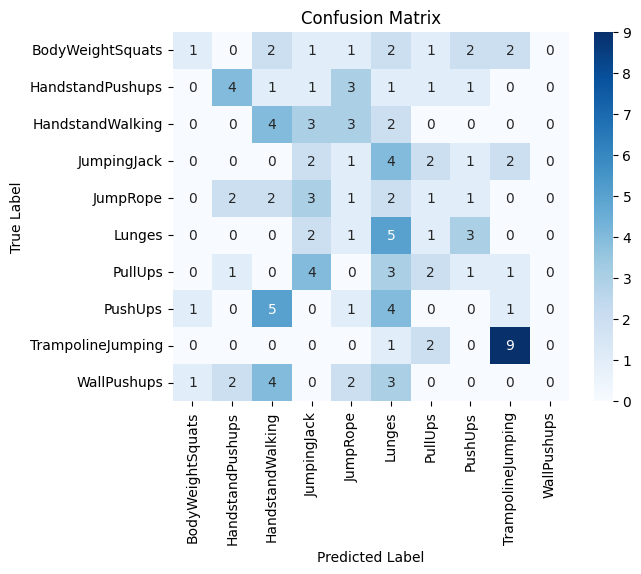

In [19]:
eval_data, TP, FP, FN, TN = validate_CNN(model, test_loader, device, action)

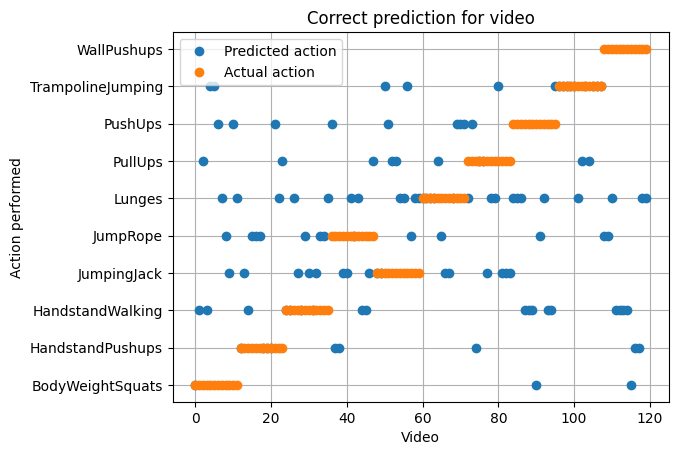

In [16]:
predicted, actual = aggregate(model, test_loader, device)

fig, ax = plt.subplots(1, 1)
ax.plot(predicted, 'o')
ax.plot(actual, 'o')
ax.set_xlabel('Video')
ax.set_ylabel('Action performed')
ax.set_title('Correct prediction for video')
ax.legend(['Predicted action', 'Actual action'])
ax.set_yticks(range(np.shape(action)[0]))
ax.set_yticklabels(action)
ax.grid()